# ITELv5 - SECCIÓN 7: PRUEBA DEL MODELO (Serving)

En esta sección, cargamos un único audio (WAV) y utilizamos el pipeline completo de ITELv5 (Preproceso, HuBERT y MLP entrenado) para predecir si la voz pertenece a 'Healthy' o 'Patients'.

In [1]:
import os
from pathlib import Path

# Asegurar que el CWD sea la carpeta de notebooks
# (IntelliJ puede configurar un CWD distinto al de Jupyter Lab)
_anchor = Path('ITELv5_01_CONFIGURACION.ipynb')
if not _anchor.exists():
    for _candidate in Path.cwd().rglob('ITELv5_01_CONFIGURACION.ipynb'):
        os.chdir(_candidate.parent)
        break
print(f'📂 CWD: {Path(".").resolve()}')


📂 CWD: C:\Users\USER\Documents\GitHub\ITEL\research\notebooks


In [2]:
# 7.1 - Configuración e importaciones
%run "./ITELv5_01_CONFIGURACION.ipynb"

import torch
import torch.nn as nn
import json
import re
from pathlib import Path
from sklearn.preprocessing import StandardScaler

print("✅ Entorno de inferencia listo.")


🔍 Verificando estructura de carpetas...
  ✅ Datos_Brutos: 1680 WAV Healthy  |  2173 WAV Patients
  ✅ Todas las dependencias disponibles.

📁 BASE_DIR : C:\Users\USER\Documents\GitHub\ITEL\research
📂 DATA_DIR : C:\Users\USER\Documents\GitHub\ITEL\research\Datos_Brutos
🖥️  GPU      : False
Rutas del proyecto ITELv5:
  Datos_Brutos    : C:\Users\USER\Documents\GitHub\ITEL\research\Datos_Brutos
  Procesados      : C:\Users\USER\Documents\GitHub\ITEL\research\processed_data
  Modelos         : C:\Users\USER\Documents\GitHub\ITEL\assets\models
  Reportes CSV    : C:\Users\USER\Documents\GitHub\ITEL\research\reports\CSV
  Reportes Figuras: C:\Users\USER\Documents\GitHub\ITEL\research\reports\Figuras
  Logs            : C:\Users\USER\Documents\GitHub\ITEL\research\logs

🔍 Healthy  : 308 subrutas de audio
🔍 Patients : 378 subrutas de audio

✅ Configuración ITELv5 lista.
✅ Entorno de inferencia listo.


📂 CWD: C:\Users\USER\Documents\GitHub\ITEL\research\notebooks
🔍 Verificando estructura de carpetas...
  ✅ Datos_Brutos: 1680 WAV Healthy  |  2173 WAV Patients
  ✅ Todas las dependencias disponibles.

📁 BASE_DIR : C:\Users\USER\Documents\GitHub\ITEL\research
📂 DATA_DIR : C:\Users\USER\Documents\GitHub\ITEL\research\Datos_Brutos
🖥️  GPU      : False
Rutas del proyecto ITELv5:
  Datos_Brutos    : C:\Users\USER\Documents\GitHub\ITEL\research\Datos_Brutos
  Procesados      : C:\Users\USER\Documents\GitHub\ITEL\research\processed_data
  Modelos         : C:\Users\USER\Documents\GitHub\ITEL\assets\models
  Reportes CSV    : C:\Users\USER\Documents\GitHub\ITEL\research\reports\CSV
  Reportes Figuras: C:\Users\USER\Documents\GitHub\ITEL\research\reports\Figuras
  Logs            : C:\Users\USER\Documents\GitHub\ITEL\research\logs

🔍 Healthy  : 308 subrutas de audio
🔍 Patients : 378 subrutas de audio

✅ Configuración ITELv5 lista.
📂 CWD: C:\Users\USER\Documents\GitHub\ITEL\research\notebooks
🔍 V

,categoria,subcarpeta,tipo,silabas,etiqueta,nombre,ruta
0,Healthy,01SAMOHL,vocal,NaN,a,4PK1A.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...
1,Healthy,01SAMOHL,vocal,NaN,e,4PK1E.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...
2,Healthy,01SAMOHL,vocal,NaN,i,4PK1I.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...
3,Healthy,01SAMOHL,vocal,NaN,o,4PK1O.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...
4,Healthy,01SAMOHL,vocal,NaN,u,4PK1U.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...



🎧 Iniciando preprocesamiento de audios...



Procesando: 100%|██████████| 3730/3730 [00:05<00:00, 694.89it/s] 


,categoria,subcarpeta,tipo,silabas,etiqueta,nombre,ruta,sr_final,estado,duracion_s
0,Healthy,01SAMOHL,vocal,NaN,a,4PK1A.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...,16000,OK,2.0
1,Healthy,01SAMOHL,vocal,NaN,e,4PK1E.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...,16000,OK,2.0
2,Healthy,01SAMOHL,vocal,NaN,i,4PK1I.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...,16000,OK,2.0
3,Healthy,01SAMOHL,vocal,NaN,o,4PK1O.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...,16000,OK,2.0
4,Healthy,01SAMOHL,vocal,NaN,u,4PK1U.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...,16000,OK,2.0



📊 Resumen de procesamiento:


estado
OK    3730
Name: count, dtype: int64


💾 Resumen exportado a: C:\Users\USER\Documents\GitHub\ITEL\research\reports\CSV\preprocesamiento_resumen_v5.csv

🎙️ Ejemplo de preprocesamiento: C:\Users\USER\Documents\GitHub\ITEL\research\Datos_Brutos\Healthy\H33\04_2SL\4TB4PAP.wav
💾 Gráfico de onda guardado en C:\Users\USER\Documents\GitHub\ITEL\research\reports\Figuras\onda_preprocesamiento_v5.png


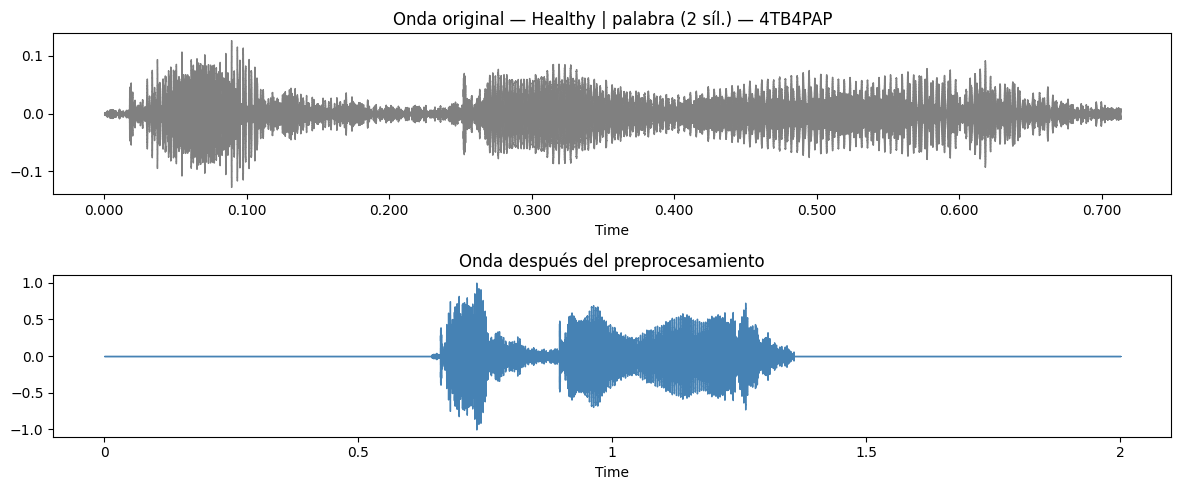


✅ Sección 4 (v5) completada. Listo para extracción de embeddings (Sección 5).
🖥️  Usando dispositivo: cpu
✅ Modelo HuBERT cargado (solo extracción de embeddings).
✅ 3730 audios listos para procesar.


,categoria,subcarpeta,tipo,silabas,etiqueta,nombre,ruta
0,Healthy,01SAMOHL,vocal,NaN,a,4PK1A.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...
1,Healthy,01SAMOHL,vocal,NaN,e,4PK1E.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...
2,Healthy,01SAMOHL,vocal,NaN,i,4PK1I.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...
3,Healthy,01SAMOHL,vocal,NaN,o,4PK1O.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...
4,Healthy,01SAMOHL,vocal,NaN,u,4PK1U.wav,C:\Users\USER\Documents\GitHub\ITEL\research\D...


📄 Cargando embeddings existentes de disco.
Shape X: (3730, 4608)


,categoria,subcarpeta,tipo,silabas,etiqueta,nombre
0,Healthy,01SAMOHL,vocal,NaN,a,4PK1A.wav
1,Healthy,01SAMOHL,vocal,NaN,e,4PK1E.wav
2,Healthy,01SAMOHL,vocal,NaN,i,4PK1I.wav
3,Healthy,01SAMOHL,vocal,NaN,o,4PK1O.wav
4,Healthy,01SAMOHL,vocal,NaN,u,4PK1U.wav


✅ Embeddings generados/cargados correctamente
 - Shape X: (3730, 4608)
 - Registros info: 3730
 - Rutas de cache:
    * C:\Users\USER\Documents\GitHub\ITEL\research\processed_data\embeddings_v5.npy
    * C:\Users\USER\Documents\GitHub\ITEL\research\processed_data\embeddings_info_v5.csv


,categoria,subcarpeta,tipo,silabas,etiqueta,nombre
0,Healthy,01SAMOHL,vocal,NaN,a,4PK1A.wav
1,Healthy,01SAMOHL,vocal,NaN,e,4PK1E.wav
2,Healthy,01SAMOHL,vocal,NaN,i,4PK1I.wav
3,Healthy,01SAMOHL,vocal,NaN,o,4PK1O.wav
4,Healthy,01SAMOHL,vocal,NaN,u,4PK1U.wav


✅ Pipeline de inferencia (preprocesamiento + embeddings + MLP) listo.


In [3]:
# 7.2 - Cargar pipeline completo desde notebooks de investigación
# Importamos preprocesamiento (04) y embeddings (05) directamente,
# evitando duplicar código. Esto garantiza que cualquier corrección
# en esos notebooks se aplique automáticamente aquí.
%run "./ITELv5_05_EMBEDDINGS.ipynb"  # también ejecuta 04 y 01 internamente
                                      # define: procesar_audio, extraer_embedding,
                                      # hubert_model, device

# --- Clase MLP (de 06_TRAINING) ---
class MLP(nn.Module):
    def __init__(self, in_dim=4608, hidden=512, dropout=0.3, num_classes=2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden, hidden//2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(hidden//2, num_classes)
        )
    def forward(self, x):
        return self.net(x)

print("✅ Pipeline de inferencia (preprocesamiento + embeddings + MLP) listo.")


In [4]:
# 7.3 - Cargar Modelos Entrenados, Scaler y Meta-Modelo (Stacking)
import joblib
import numpy as np

N_SPLITS = 5
models = []
scaler = None
meta_model = None

try:
    # 1. Cargar Hiperparámetros del MLP (guardados en notebook 06)
    hparams_path = ITELConfig.MODELS_DIR / 'mlp_hparams_v5.json'
    with open(hparams_path, 'r') as f:
        hparams = json.load(f)
    print(f"HParams MLP: {hparams}")

    # 2. Cargar el Scaler (ajustado sobre el 80 % en notebook 06)
    scaler_path = ITELConfig.MODELS_DIR / 'linear_head_scaler.npz'
    scaler_data = np.load(scaler_path)
    from sklearn.preprocessing import StandardScaler
    scaler = StandardScaler()
    scaler.mean_  = scaler_data['mean']
    scaler.scale_ = scaler_data['scale']
    print(f"Scaler cargado desde: {scaler_path}")

    # 3. Cargar los 5 modelos MLP base (un por fold del 80 %)
    for i in range(1, N_SPLITS + 1):
        model_path = ITELConfig.MODELS_DIR / f'itelv5_mlp_fold_{i}.pt'
        model = MLP(
            in_dim=4608,
            hidden=hparams['hidden'],
            dropout=hparams['dropout']
        ).to(device)
        model.load_state_dict(torch.load(model_path, map_location=device))
        model.eval()
        models.append(model)
    print(f"✅ {len(models)} modelos MLP base cargados.")

    # 4. Cargar el meta-modelo LogReg (entrenado en notebook 08 sobre el 10 %)
    meta_path = ITELConfig.MODELS_DIR / 'final_meta_model_v5.joblib'
    meta_model = joblib.load(meta_path)
    print(f"✅ Meta-modelo de stacking cargado desde: {meta_path}")

except FileNotFoundError as e:
    print(f"⚠️  Archivo no encontrado: {e}")
    print("Asegúrate de haber ejecutado los notebooks 06 y 08 completos.")
except Exception as e:
    print(f"❌ Error inesperado: {e}")
    raise


HParams MLP: {'dropout': 0.3, 'epochs': 100, 'hidden': 256, 'lr': 0.001, 'weight_decay': 1e-05}
Scaler cargado desde: C:\Users\USER\Documents\GitHub\ITEL\assets\models\linear_head_scaler.npz
✅ 5 modelos MLP base cargados.
✅ Meta-modelo de stacking cargado desde: C:\Users\USER\Documents\GitHub\ITEL\assets\models\final_meta_model_v5.joblib


In [5]:
# 7.4 - Función de Inferencia (Stacking)
#
# Pipeline:
#   audio → embedding (4608 d) → scaler → 5 MLP base models
#        → stack probs (1×10) → LogReg meta-model → predicción final

def predecir_audio(ruta_archivo):
    """Predice clase (Healthy / Patients) usando el pipeline de stacking."""
    print(f"\nProcesando: {ruta_archivo}...")

    if meta_model is None or not models:
        print("❌ Modelos no cargados. Ejecuta la celda 7.3 primero.")
        return

    # 1. Extraer embedding HuBERT (4608 dims)
    embedding = extraer_embedding(ruta_archivo)
    if embedding is None:
        print("❌ No se pudo procesar el audio.")
        return

    # 2. Escalar con el scaler del 80 %
    embedding_scaled = scaler.transform(embedding.reshape(1, -1))  # (1, 4608)
    emb_tensor = torch.tensor(embedding_scaled, dtype=torch.float32).to(device)

    # 3. Obtener probabilidades de los 5 modelos base
    probs_list = []
    with torch.inference_mode():
        for model in models:
            logits = model(emb_tensor)                        # (1, 2)
            probs  = torch.softmax(logits, dim=1).cpu().numpy()  # (1, 2)
            probs_list.append(probs)

    # 4. Construir vector de stacking (1×10)
    X_stack = np.hstack(probs_list)  # (1, 10) → [p0_H, p0_P, p1_H, p1_P, ...]

    # 5. Meta-modelo LogReg → predicción final
    pred_idx   = meta_model.predict(X_stack)[0]               # 0 ó 1
    pred_proba = meta_model.predict_proba(X_stack)[0]         # [p_H, p_P]
    confianza  = pred_proba[pred_idx]

    label_map_inv = {0: 'Healthy', 1: 'Patients'}
    resultado = label_map_inv[pred_idx]

    print("────────── RESULTADO DE LA PREDICCIÓN ──────────")
    print(f"  Diagnóstico : {resultado}")
    print(f"  Confianza   : {confianza * 100:.2f}%")
    print(f"  (Healthy: {pred_proba[0]:.3f}  |  Patients: {pred_proba[1]:.3f})")
    print("─────────────────────────────────────────────────")

    # 6. Visualizar la onda preprocesada
    try:
        y_proc, sr_proc, _ = procesar_audio(ruta_archivo)
        plt.figure(figsize=(10, 3))
        librosa.display.waveshow(y_proc, sr=sr_proc, color='steelblue')
        plt.title(f"Onda procesada (2 s, 16 kHz) — {Path(ruta_archivo).name}")
        plt.tight_layout()
        plt.show()
    except Exception as e:
        print(f"(No se pudo graficar la onda: {e})")

    return resultado, confianza


In [6]:
# 7.5 - ¡Prueba aquí! Sube tu archivo WAV

import ipywidgets as widgets
from IPython.display import display

print("Por favor, usa el siguiente botón para subir tu archivo WAV:")

# 1. Crear el widget de carga de archivos
uploader = widgets.FileUpload(
    accept='.wav',  # Aceptar solo archivos .wav
    multiple=False  # No permitir subir múltiples archivos
)

# 2. Mostrar el widget
display(uploader)

print("\n...una vez que hayas subido el archivo, ejecuta la siguiente celda (7.6).")

Por favor, usa el siguiente botón para subir tu archivo WAV:


FileUpload(value=(), accept='.wav', description='Upload')


...una vez que hayas subido el archivo, ejecuta la siguiente celda (7.6).


✅ Archivo '401_SPEAKER_00.wav' recibido.

Procesando: 401_SPEAKER_00.wav...
────────── RESULTADO DE LA PREDICCIÓN ──────────
  Diagnóstico : Patients
  Confianza   : 93.77%
  (Healthy: 0.062  |  Patients: 0.938)
─────────────────────────────────────────────────


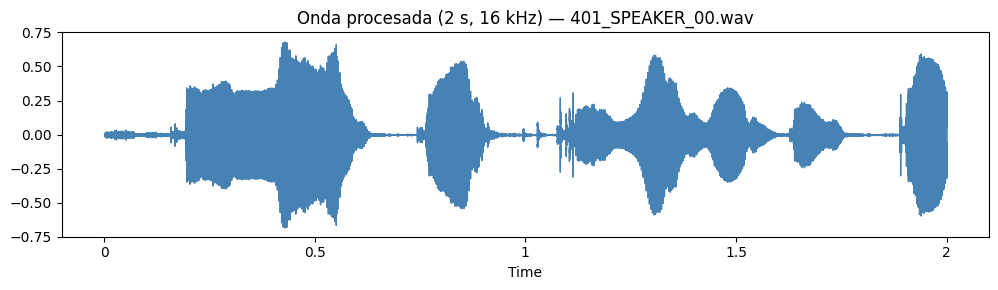

In [11]:
# 7.6 - Procesar el audio subido

# 1. Verificar si se subió un archivo
if not uploader.value:
    print("⚠️ No se ha subido ningún archivo. Por favor, sube un archivo .wav en la celda 7.5 y vuelve a ejecutar esta celda.")
else:
    try:
        # 2. Obtener la información del archivo subido
        #    Compatible con ipywidgets >= 7 (tuple) y >= 8 (dict)
        _val = uploader.value
        if isinstance(_val, dict):
            file_info = next(iter(_val.values()))
        else:
            file_info = _val[0]

        file_name    = file_info['name']
        file_content = file_info['content']

        # 3. Guardar el archivo temporalmente en disco para que librosa pueda leerlo
        temp_path = Path(f"./{file_name}")
        with open(temp_path, 'wb') as f:
            f.write(bytes(file_content))

        print(f"✅ Archivo '{file_name}' recibido.")

        # 4. Llamar a la función de predicción (definida en la celda 7.4)
        predecir_audio(temp_path)

        # 5. Eliminar el archivo temporal
        temp_path.unlink()

        # 6. Limpiar el widget para la próxima subida
        uploader.value = ()

    except Exception as e:
        print(f"❌ Ocurrió un error al procesar el archivo: {e}")
        if 'temp_path' in locals() and Path(temp_path).exists():
            Path(temp_path).unlink()
